# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
from aitlas.datasets import NeonTreeDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 211


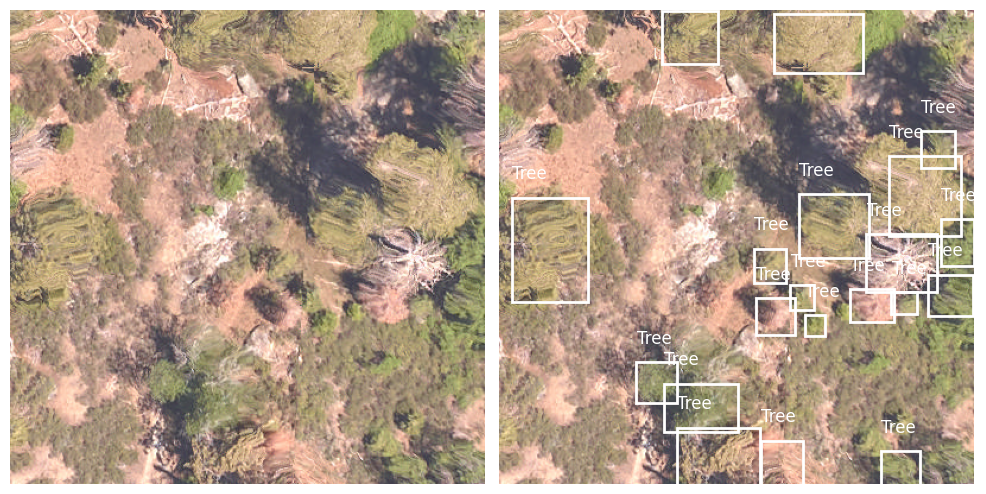

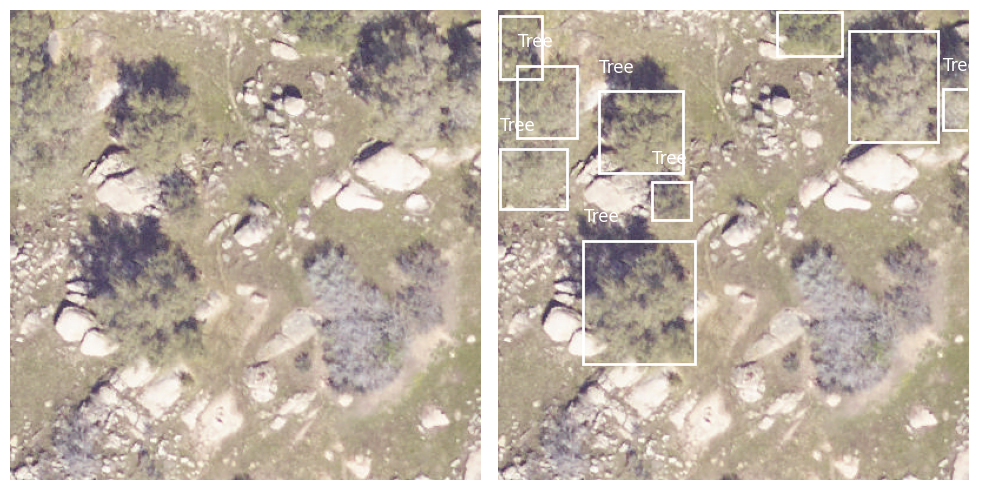

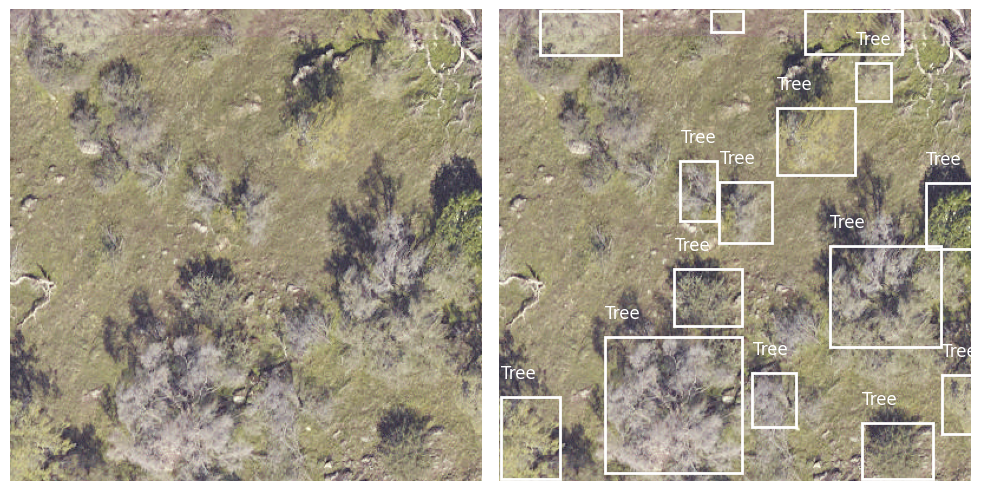

In [5]:
dataset_config = {
    "image_dir": "/home/dragik/data/FAIR_EO/neontree/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/neontree/annotations/",
}
dataset = NeonTreeDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

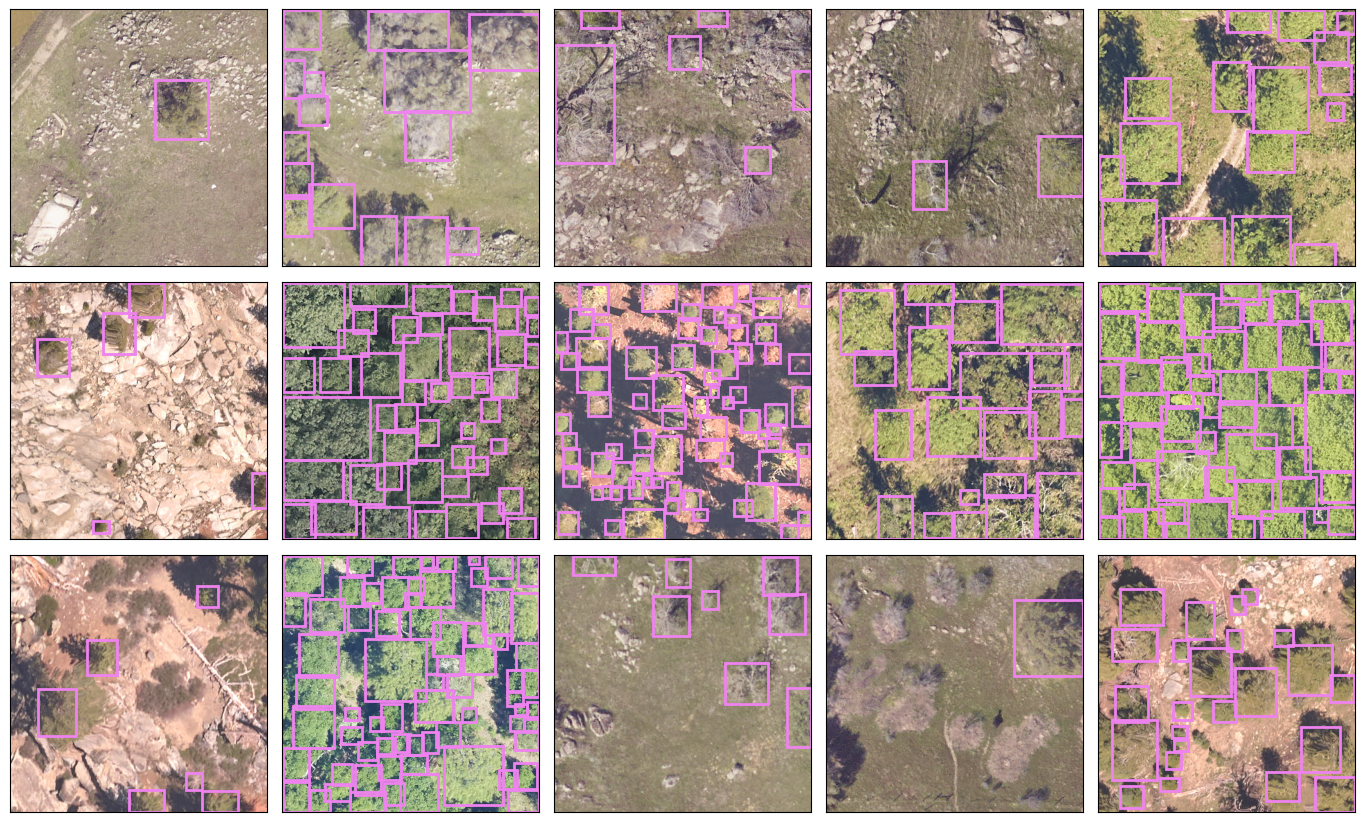

In [27]:
dataset.show_batch(15);

In [28]:
dataset.data_distribution_table()

,Label,Count
0,Tree,30098


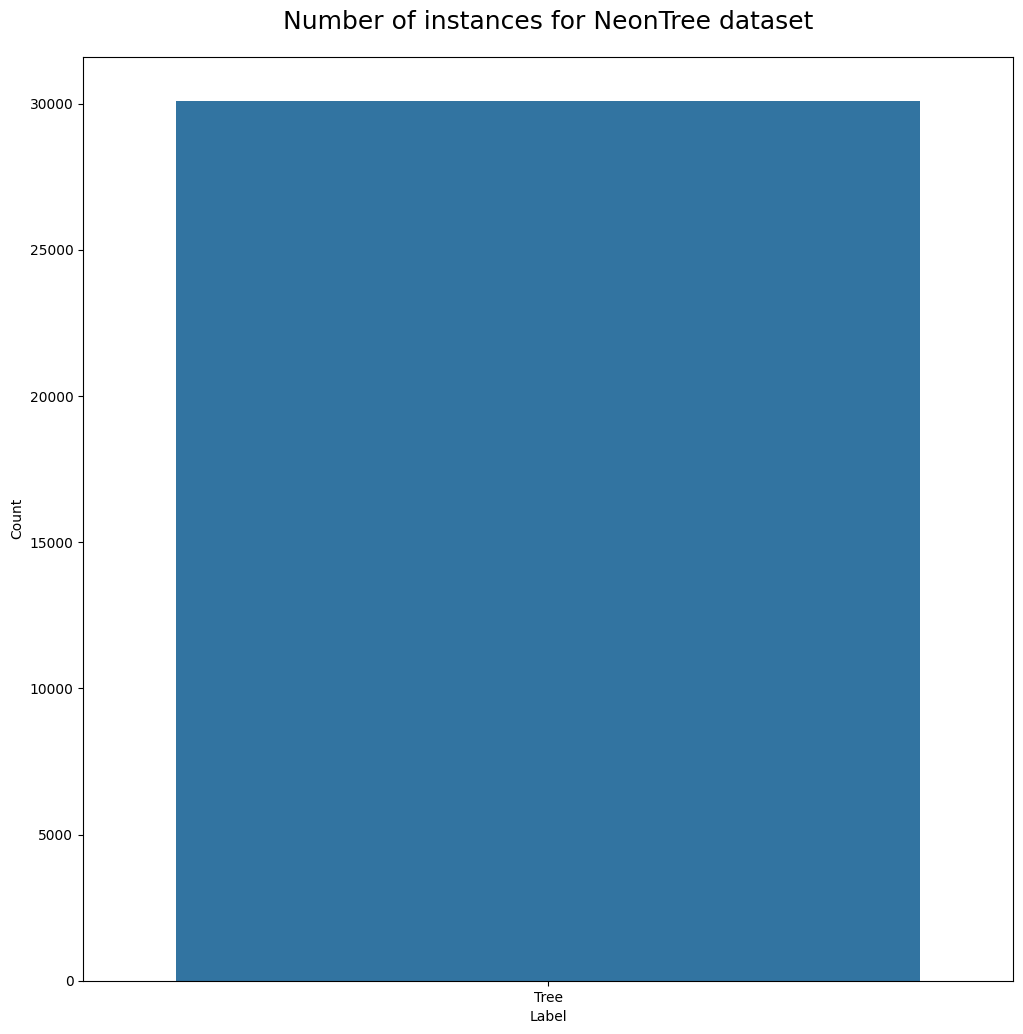

In [29]:
dataset.data_distribution_barchart();

## Load train data

In [6]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "image_dir": "/home/dragik/data/FAIR_EO/neontree/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/neontree/annotations/",
    "csv_file":"/home/dragik/data/FAIR_EO/neontree/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = NeonTreeDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 17


## Create the model

In [7]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/neontree/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [8]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-28 08:48:07,456 INFO Starting training.
training: 100%|██████████| 3/3 [00:11<00:00,  3.94s/it]
2025-05-28 08:48:19,674 INFO epoch: 1, time: 12, loss:  6.05099
testing on train set: 100%|██████████| 3/3 [00:11<00:00,  3.79s/it]
2025-05-28 08:48:51,010 INFO map:0.002258368767797947, map_50:0.009900989942252636, map_75:0.0005657708388753235, map_small:0.0022586144041270018, map_medium:0.0006191826541908085, map_large:-1.0, mar_1:1.561646058689803e-05, mar_10:0.00021082221064716578, mar_100:0.00167876947671175, mar_small:0.0016007532831281424, mar_medium:0.01746031828224659, mar_large:-1.0, map_per_class:0.002258368767797947, mar_100_per_class:0.00167876947671175, classes:1.0
training: 100%|██████████| 3/3 [00:10<00:00,  3.55s/it]
2025-05-28 08:49:01,672 INFO epoch: 2, time: 10, loss:  3.13603
testing on train set: 100%|██████████| 3/3 [00:11<00:00,  3.93s/it]
2025-05-28 08:49:31,998 INFO map:0.00031464631319977343, map_50:0.0009633395820856094, map_75:0.0001646734308451414, map_s

## Evaluate the model

In [9]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "/home/dragik/data/FAIR_EO/neontree/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/neontree/annotations/",
    "csv_file":"/home/dragik/data/FAIR_EO/neontree/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = NeonTreeDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/neontree/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 194


2025-05-28 09:28:11,152 INFO Loading checkpoint /home/dragik/data/FAIR_EO/neontree/checkpoint.pth.tar
2025-05-28 09:28:11,598 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/neontree/checkpoint.pth.tar at epoch 51
testing on test set: 100%|██████████| 25/25 [00:05<00:00,  4.50it/s]


[{'map': 0.001895665773190558,
  'map_50': 0.00652178144082427,
  'map_75': 0.0007322259480133653,
  'map_small': 0.0034053402487188578,
  'map_medium': 0.007243150379508734,
  'map_large': 0.0,
  'mar_1': 0.0007990351296029985,
  'mar_10': 0.0049148197285830975,
  'mar_100': 0.02617216855287552,
  'mar_small': 0.05616713687777519,
  'mar_medium': 0.008718080818653107,
  'mar_large': 0.0,
  'map_per_class': 0.001895665773190558,
  'mar_100_per_class': 0.02617216855287552,
  'classes': 1.0}]

## Predictions

2025-05-28 09:32:11,467 INFO Loading checkpoint /home/dragik/data/FAIR_EO/neontree/checkpoint.pth.tar
2025-05-28 09:32:11,873 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/neontree/checkpoint.pth.tar at epoch 51


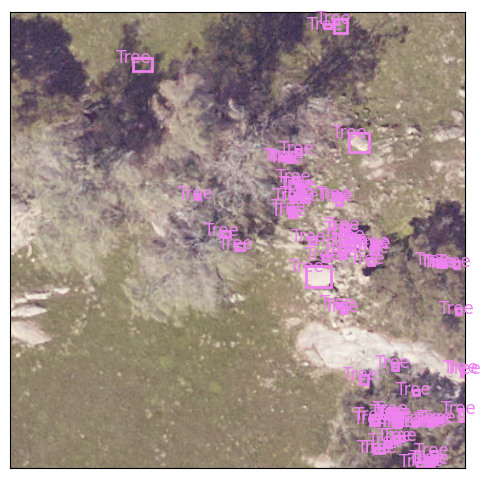

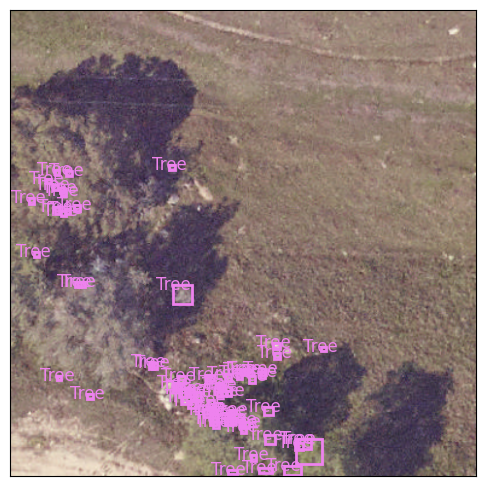

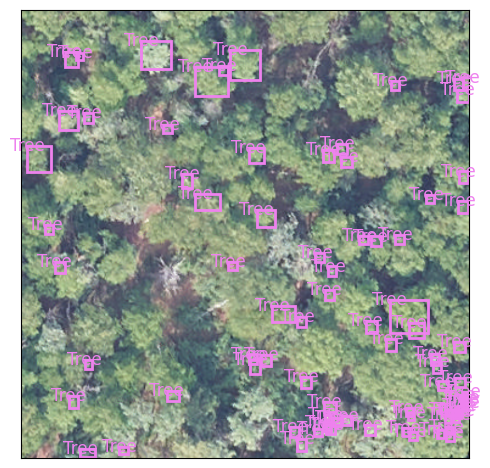

In [10]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/neontree/checkpoint.pth.tar"
labels = ['no-data','Tree']
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/neontree/images/2018_SJER_3_252000_4107000_image_477.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/neontree/images/2018_SJER_3_254000_4108000_image_188.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/neontree/images/BONA_012_2019.tif')
fig = model.detect_objects(image, labels, transform)